2026-11-03 수업
- 기본 연산 및 화소 처리 일부

In [2]:
# 공통부분이기 때문에 실습을 새로운 notebook에서 할때마다 복사해서 실행
import sys
sys.path.append('../multi_info/common') # 모듈이 존재하는 path를 추가
import cvnb
import cv2

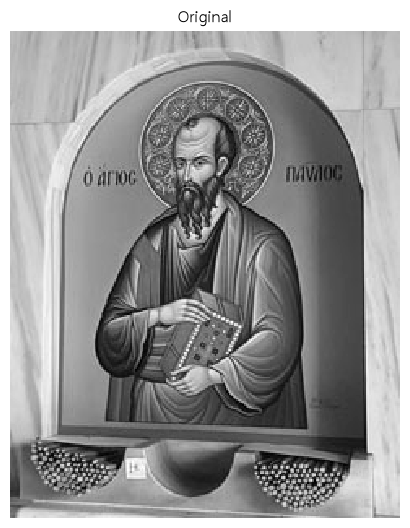

In [3]:
image = cv2.imread("../multi_info/images/pixel.jpg", cv2.IMREAD_GRAYSCALE)
cv2.imshow("Original", image)

In [4]:
import numpy as np
avg = np.average(image)
print(f"average of image: {avg}")

average of image: 135.91027777777776


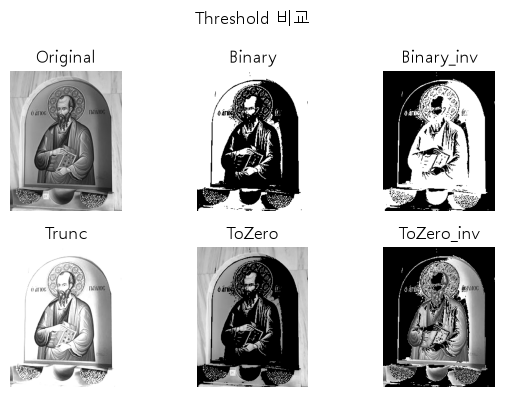

In [5]:
avg = int(avg)
_, bin_img = cv2.threshold(image, avg, 255, cv2.THRESH_BINARY)
_, bini_img = cv2.threshold(image, avg, 255, cv2.THRESH_BINARY_INV)
_, trunc_img = cv2.threshold(image, avg, 255, cv2.THRESH_TRUNC)
_, zero_img = cv2.threshold(image, avg, 255, cv2.THRESH_TOZERO)
_, zeroi_img = cv2.threshold(image, avg, 255, cv2.THRESH_TOZERO_INV)

import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
images = [image, bin_img, bini_img, trunc_img, zero_img, zeroi_img]
titles = ['Original', 'Binary', 'Binary_inv', 'Trunc', 'ToZero', 'ToZero_inv']

for i, (title, image) in enumerate(zip(titles, images)):
    plt.subplot(2, 3, i+1)
    plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.axis('off')
plt.suptitle('Threshold 비교')

plt.tight_layout()
plt.show()

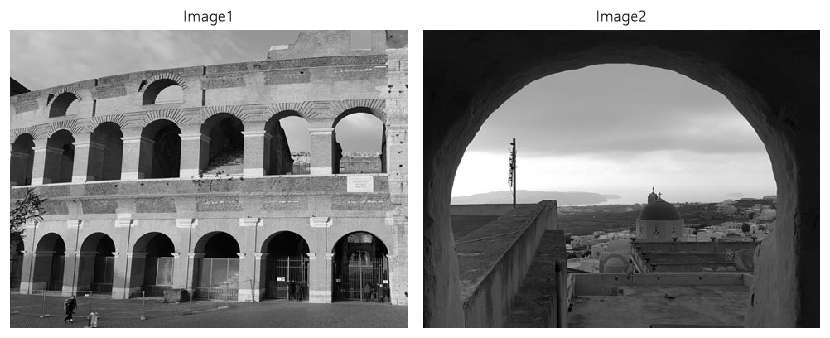

In [6]:
image1 = cv2.imread("../multi_info/images/abs_test1.jpg", cv2.IMREAD_GRAYSCALE)
image2 = cv2.imread("../multi_info/images/abs_test2.jpg", cv2.IMREAD_GRAYSCALE)
cv2.imshow("Image1", image1)
cv2.imshow("Image2", image2)

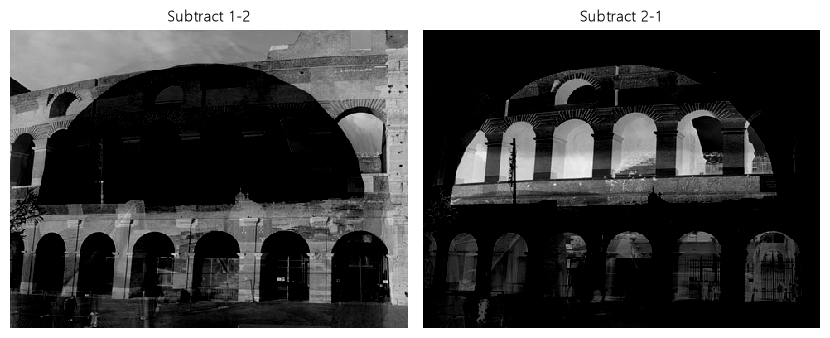

In [7]:
sub1 = cv2.subtract(image1, image2)
sub2 = cv2.subtract(image2, image1)
cv2.imshow("Subtract 1-2", sub1)
cv2.imshow("Subtract 2-1", sub2)

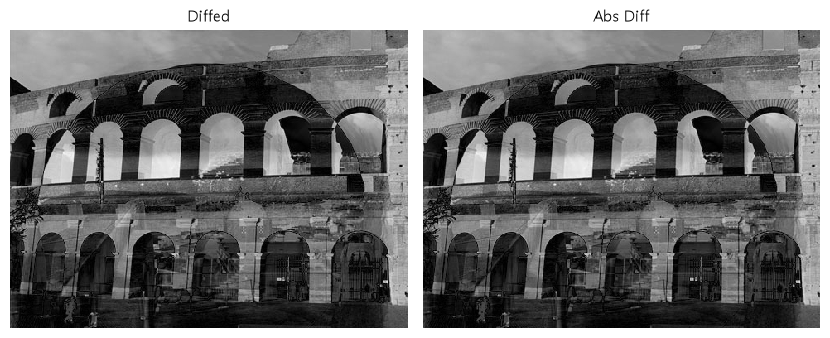

In [8]:
diff_added = cv2.add(sub1, sub2)
cv2.imshow("Diffed", diff_added)
abs_diff = cv2.absdiff(image1, image2)
cv2.imshow("Abs Diff", abs_diff)

<class 'numpy.ndarray'>, <class 'numpy.ndarray'>
min = 0, max=255


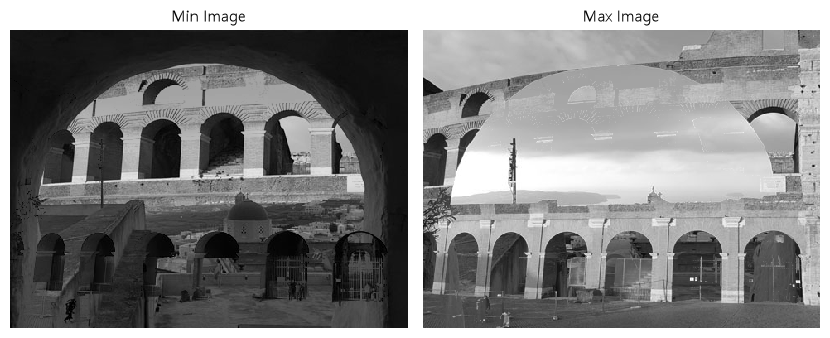

In [9]:
# min, max value
min_image = cv2.min(image1, image2)
max_image = cv2.max(image1, image2)
print(f"{type(min_image)}, {type(max_image)}")
print(f"min = {np.min(min_image)}, max={np.max(max_image)}")
cv2.imshow("Min Image", min_image)
cv2.imshow("Max Image", max_image)

## gemm (일반 행렬 연산)

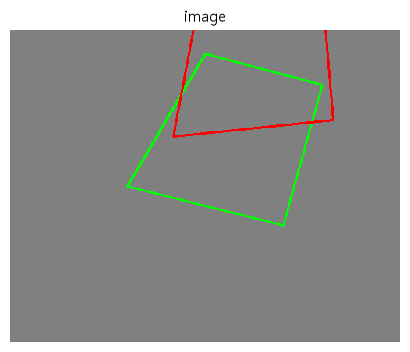

In [10]:
import numpy as np
theta = 20 * np.pi / 180
rot_mat = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]], np.float32)
pts1 = np.array([[250, 30], [400, 70], [350, 250], [150, 200]], np.float32)
pts2 = cv2.gemm(pts1, rot_mat, 1, None, 1)
image = np.full((400,500,3), 128, np.uint8)
cv2.polylines(image, [np.int32(pts1)], True, (0, 255, 0), 2)
cv2.polylines(image, [np.int32(pts2)], True, (0, 0, 255), 2)
cv2.imshow("image", image)